In [ ]:
import pandas as pd

df = pd.read_csv("/content/Unemployment in India.csv")

In [ ]:
df

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.shape

(768, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [ ]:
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


In [ ]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [ ]:
# Remove rows where all values are missing
df.dropna(how='all', inplace=True)

df.isnull().sum()

,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


In [ ]:
df.shape

(740, 7)

In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [ ]:
df['Date'].dtype

dtype('O')

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

df['Date'].dtype

dtype('<M8[ns]')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.2+ KB


##Exploratory Data Analysis (EDA)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

region_avg = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean()

region_avg = region_avg.sort_values(ascending=False)

region_avg

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


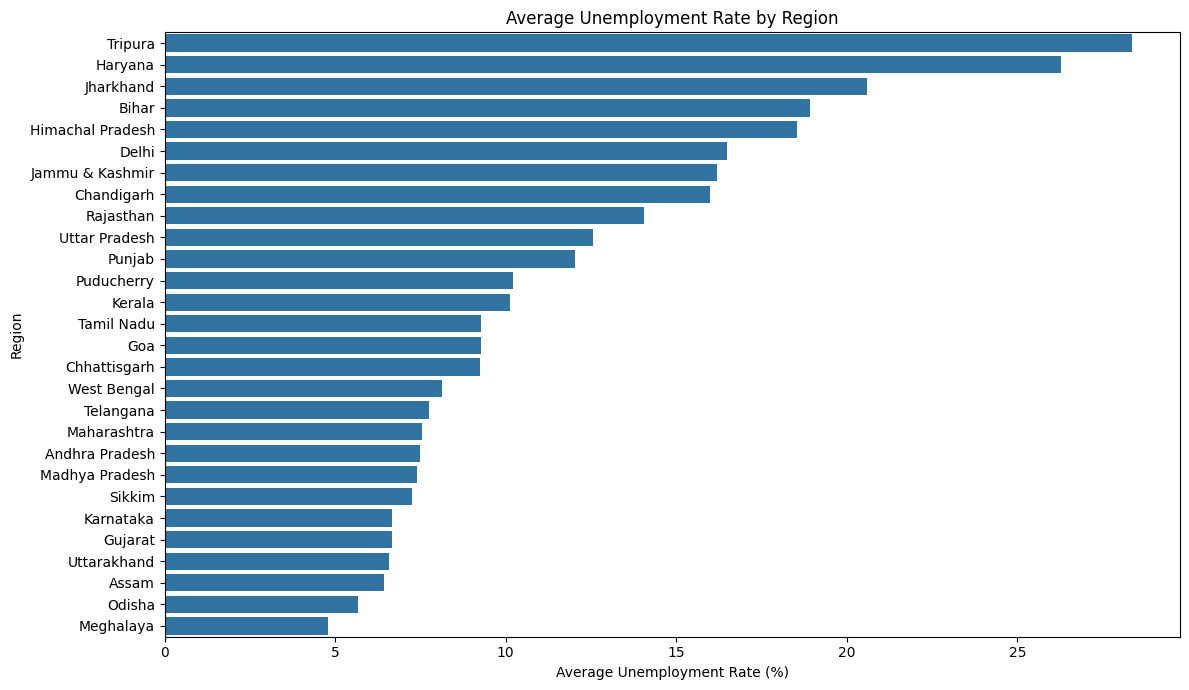

In [ ]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=region_avg.values,
    y=region_avg.index
)

plt.title('Average Unemployment Rate by Region')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

Observation: Tripura recorded the highest average unemployment rate at approximately 28.35%, followed by Haryana at 26.28%. Meghalaya had the lowest average rate at approximately 4.80%. This shows considerable variation in unemployment levels across different regions of India.

In [ ]:
monthly_avg = df.groupby('Date')['Estimated Unemployment Rate (%)'].mean()

monthly_avg

,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


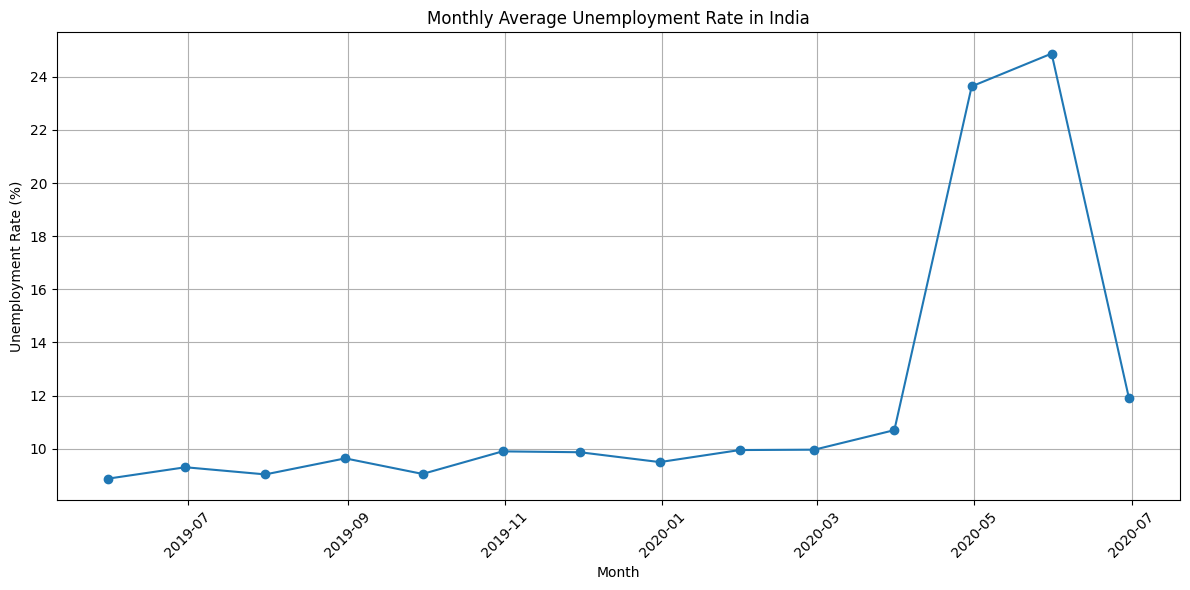

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_avg.index, monthly_avg.values, marker='o')

plt.title('Monthly Average Unemployment Rate in India')
plt.xlabel('Month')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Observation: The unemployment rate increased sharply during April and May 2020, reaching approximately 23.64% and 24.88%, respectively. This rise coincides with the COVID-19 lockdown period, indicating a significant impact on employment in India.

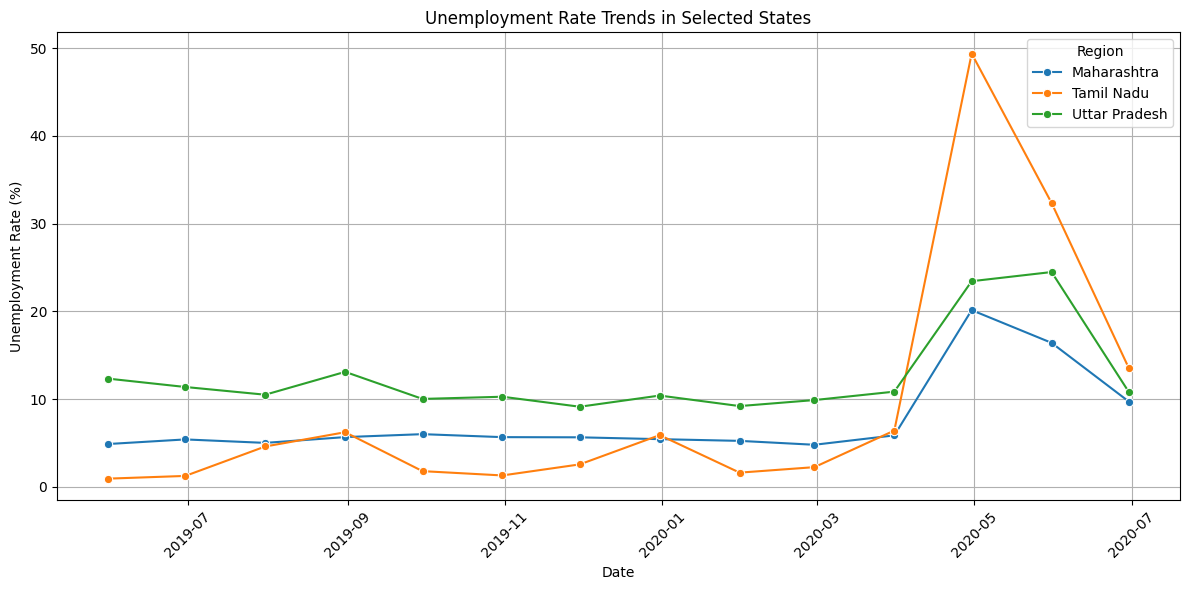

In [ ]:
#state-wise unemployment trend
states = ['Maharashtra', 'Uttar Pradesh', 'Tamil Nadu']

state_data = df[df['Region'].isin(states)]

state_monthly = state_data.groupby(
    ['Date', 'Region']
)['Estimated Unemployment Rate (%)'].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_monthly,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    hue='Region',
    marker='o'
)

plt.title('Unemployment Rate Trends in Selected States')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Observation: Among the three selected states, Tamil Nadu experienced the sharpest increase in unemployment around April–May 2020. Maharashtra and Uttar Pradesh showed different trends, indicating that the impact of the COVID-19 lockdown varied across states.

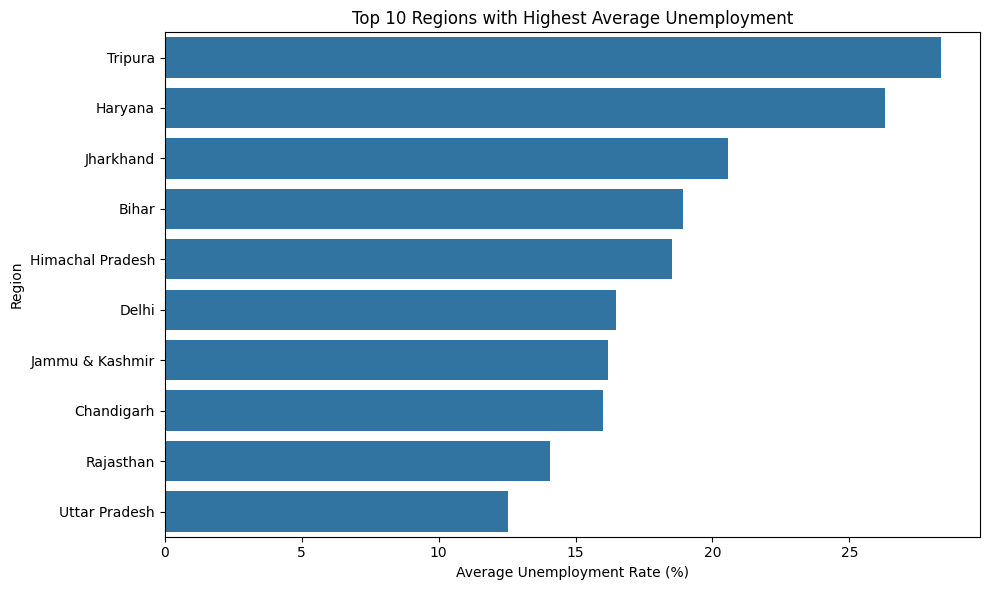

In [ ]:
#Top 10 regions with the highest average unemployment
top_10 = region_avg.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10.values,
    y=top_10.index
)

plt.title('Top 10 Regions with Highest Average Unemployment')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

Observation: Tripura recorded the highest average unemployment rate, followed by Haryana and Jharkhand. The top 10 regions show that unemployment levels were considerably higher in some regions than others.

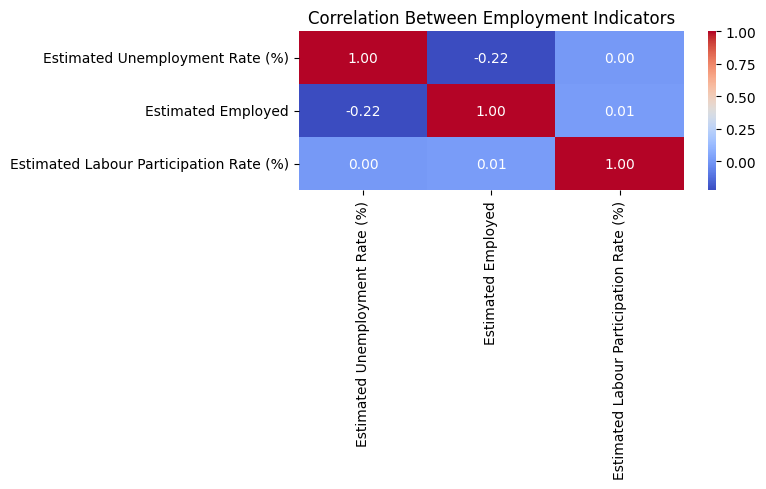

In [ ]:
#Correlation heatmap
correlation = df[
    [
        'Estimated Unemployment Rate (%)',
        'Estimated Employed',
        'Estimated Labour Participation Rate (%)'
    ]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Employment Indicators')

plt.tight_layout()
plt.show()

Observation: The correlation heatmap shows the relationships between unemployment rate, estimated employment, and labour participation rate. Positive correlation indicates that two variables tend to increase together, while negative correlation indicates that one tends to decrease as the other increases. The strength of each relationship can be understood from the correlation values.

**Pre-COVID vs Post-COVID comparison**

In [ ]:
pre_covid = df[df['Date'] < '2020-03-01']

post_covid = df[df['Date'] >= '2020-03-01']

pre_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()

post_avg = post_covid['Estimated Unemployment Rate (%)'].mean()

print("Pre-COVID Average Unemployment Rate:", round(pre_avg, 2), "%")
print("Post-COVID Average Unemployment Rate:", round(post_avg, 2), "%")

Pre-COVID Average Unemployment Rate: 9.51 %
Post-COVID Average Unemployment Rate: 17.77 %


Observation: The average unemployment rate increased from 9.51% before COVID-19 to 17.77% after March 2020. This indicates a significant rise in unemployment during the pandemic period, reflecting the impact of lockdowns and economic disruptions on employment in India.

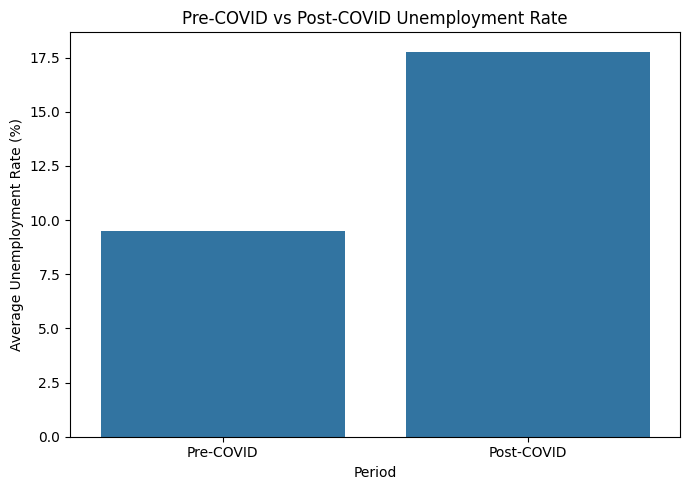

In [ ]:
covid_comparison = pd.Series({
    'Pre-COVID': pre_avg,
    'Post-COVID': post_avg
})

plt.figure(figsize=(7, 5))

sns.barplot(
    x=covid_comparison.index,
    y=covid_comparison.values
)

plt.title('Pre-COVID vs Post-COVID Unemployment Rate')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')

plt.tight_layout()
plt.show()

## Conclusion

The analysis of unemployment in India revealed significant regional differences and a sharp increase in unemployment during the COVID-19 period. Tripura recorded the highest average unemployment rate among the regions analysed. The comparison also showed that the average unemployment rate increased from 9.51% before COVID-19 to 17.77% after March 2020. Visualizations helped identify regional patterns, monthly trends, and relationships between employment indicators.